#Ngày 1: Tensor và shape


Import và Device

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


Tạo tensor

In [ ]:
scalar = torch.tensor(7.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
])

image = torch.randn(1, 28, 28)  # (C, H, W) or (Channel, Height, Width)
rgb_image = torch.randn(3, 224, 224)
batch = torch.randn(16, 3, 224, 224) # (B, C, H, W) or (Batch size, Channel, Height, Width)
# Có 16 ảnh RGB, mỗi ảnh 224x224

tensors = {
    "scalar": scalar,
    "vector": vector,
    "matrix": matrix,
    "grayscale image": image,
    "RGB image": rgb_image,
    "batch RGB images": batch,
}

for name, x in tensors.items():
    print(
        f"{name:20s} | shape={tuple(x.shape)} | "
        f"ndim={x.ndim} | dtype={x.dtype} | device={x.device}"
    )

scalar               | shape=() | ndim=0 | dtype=torch.float32 | device=cpu
vector               | shape=(3,) | ndim=1 | dtype=torch.float32 | device=cpu
matrix               | shape=(2, 3) | ndim=2 | dtype=torch.float32 | device=cpu
grayscale image      | shape=(1, 28, 28) | ndim=3 | dtype=torch.float32 | device=cpu
RGB image            | shape=(3, 224, 224) | ndim=3 | dtype=torch.float32 | device=cpu
batch RGB images     | shape=(16, 3, 224, 224) | ndim=4 | dtype=torch.float32 | device=cpu


Exercise

In [ ]:
import torch

gray_batch = torch.randn(32, 1, 64, 64)
rgb_batch = torch.randn(8, 3, 512, 512)
patch_features = torch.randn(1000, 768)
slide_features = torch.randn(16, 500, 768) # (S, P, D) or (Slide, Patch, Dimension Embedding)

print(gray_batch.shape)
print(rgb_batch.shape)
print(patch_features.shape)
print(slide_features.shape)

torch.Size([32, 1, 64, 64])
torch.Size([8, 3, 512, 512])
torch.Size([1000, 768])
torch.Size([16, 500, 768])


#Ngày 2: tensor operations và broadcasting

In [ ]:
x = torch.tensor([1.0, 2.0, 3.0])
y = torch.tensor([10.0, 20.0, 30.0])

print("x + y =", x + y)
print("x * y =", x * y)
print("mean(x) =", x.mean()) # ~ Average
print("sum(x) =", x.sum())
print("norm(x) =", torch.norm(x)) # Tính chuẩn L2 (Độ dài Vector)
# = sqrt(1^2 + 2^2 + 3^2) = sqrt(14) ~ 3.7417

x + y = tensor([11., 22., 33.])
x * y = tensor([10., 40., 90.])
mean(x) = tensor(2.)
sum(x) = tensor(6.)
norm(x) = tensor(3.7417)


matrix multiplication

In [ ]:
A = torch.randn(3, 4)
B = torch.randn(4, 2)

C = A @ B

print("A:", A.shape)
print("B:", B.shape)
print("C = A @ B:", C.shape) # (m, n) @ (n, p) = (m, p)

A: torch.Size([3, 4])
B: torch.Size([4, 2])
C = A @ B: torch.Size([3, 2])


broadcasting

In [ ]:
# 1. Tạo batch gồm 8 ảnh, mỗi ảnh có 3 kênh màu (RGB), kích thước 224x224
images = torch.randn(8, 3, 224, 224)

# 2. Tính giá trị trung bình riêng cho từng kênh màu (RGB) trên toàn bộ 8 ảnh.
# Kết quả có shape (1, 3, 1, 1) nhờ keepdim=True để giữ nguyên cấu trúc 4D.
channel_mean = images.mean(dim=(0, 2, 3), keepdim=True)

# 3. Trừ ảnh gốc cho giá trị trung bình vừa tính (Zero-centering).
# Nhờ cơ chế tự co giãn (Broadcasting), shape kết quả giữ nguyên (8, 3, 224, 224).
centered_images = images - channel_mean

print("images:", images.shape)
print("channel_mean:", channel_mean.shape)
print("centered_images:", centered_images.shape)

images: torch.Size([8, 3, 224, 224])
channel_mean: torch.Size([1, 3, 1, 1])
centered_images: torch.Size([8, 3, 224, 224])


Tạo batch giả dạng (10, 1, 28, 28).

Tính global mean và std.

Chuẩn hóa tensor theo công thức trên.

Kiểm tra mean và std sau normalize.

Tạo batch RGB (8, 3, 32, 32).

Normalize riêng từng channel.

In mean/std của từng channel trước và sau chuẩn hóa.

In [ ]:
import torch

# 1. Grayscale images: batch shape (10, 1, 28, 28)
gray_images = torch.randn(10, 1, 28, 28)

# Global mean and standard deviation
# mean/std are calculated over all pixels of all images
gray_mean = gray_images.mean()
gray_std = gray_images.std()

# Normalize: mean -> ~0, std -> ~1
gray_norm = (gray_images - gray_mean) / gray_std

print("=== Grayscale ===")
print("Shape:", gray_images.shape)
print("Before  | mean:", gray_images.mean().item(),
      "| std:", gray_images.std().item())
print("After   | mean:", gray_norm.mean().item(),
      "| std:", gray_norm.std().item())


# 2. RGB images: batch shape (8, 3, 32, 32)
rgb_images = torch.randn(8, 3, 32, 32)

# Calculate mean/std separately for R, G, B
# dim=(0,2,3): average over batch, height and width
# keepdim=True -> shape becomes (1, 3, 1, 1)
rgb_mean = rgb_images.mean(dim=(0, 2, 3), keepdim=True)
rgb_std = rgb_images.std(dim=(0, 2, 3), keepdim=True)

# Broadcasting automatically applies each channel's mean/std
rgb_norm = (rgb_images - rgb_mean) / rgb_std

print("\n=== RGB ===")
print("Shape:", rgb_images.shape)

print("Before:")
print("Mean per channel:", rgb_mean.flatten())
print("Std  per channel:", rgb_std.flatten())

# Check mean/std after normalization
after_mean = rgb_norm.mean(dim=(0, 2, 3))
after_std = rgb_norm.std(dim=(0, 2, 3))

print("After:")
print("Mean per channel:", after_mean)
print("Std  per channel:", after_std)

# Expected:
# Mean ≈ [0, 0, 0]
# Std  ≈ [1, 1, 1]

=== Grayscale ===
Shape: torch.Size([10, 1, 28, 28])
Before  | mean: -0.003557052928954363 | std: 0.9938581585884094
After   | mean: -2.4328425385355956e-10 | std: 1.0

=== RGB ===
Shape: torch.Size([8, 3, 32, 32])
Before:
Mean per channel: tensor([ 0.0063,  0.0080, -0.0031])
Std  per channel: tensor([1.0010, 0.9910, 0.9994])
After:
Mean per channel: tensor([ 1.3504e-08,  1.1874e-08, -1.1642e-09])
Std  per channel: tensor([1.0000, 1.0000, 1.0000])


# Ngày 3: Autograd — “máy tính gradient”

Autograd là thứ khiến PyTorch tự tính đạo hàm cho bạn.

Đạo hàm đơn giản

In [ ]:
x = torch.tensor(2.0, requires_grad=True)

y = x**2 + 3*x + 1

y.backward()

print("x =", x.item())
print("y =", y.item())
print("dy/dx =", x.grad.item())

x = 2.0
y = 11.0
dy/dx = 7.0


In [ ]:
import torch

x = torch.tensor(2.0, requires_grad=True)

f = 3*x**3 - 2*x**2 + 5

f.backward()

print("x =", x.item())
print("f(x) =", f.item())
print("df/dx =", x.grad.item())

x = 2.0
f(x) = 21.0
df/dx = 28.0


# Ngày 4: Gradient descent từ con số 0

Tạo dữ liệu

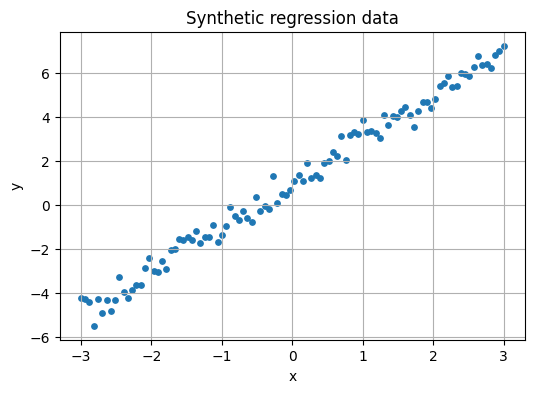

In [ ]:
torch.manual_seed(42)

x = torch.linspace(-3, 3, 100).unsqueeze(1)
noise = 0.4 * torch.randn_like(x)
y = 2.0 * x + 1.0 + noise

plt.figure(figsize=(6, 4))
plt.scatter(x.numpy(), y.numpy(), s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic regression data")
plt.grid(True)
plt.show()

tự train w,b

In [ ]:
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

learning_rate = 0.05
loss_history = []

for step in range(500):
    y_pred = w * x + b

    loss = ((y_pred - y) ** 2).mean()

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())

    if step % 100 == 0:
        print(
            f"step={step:03d} "
            f"loss={loss.item():.4f} "
            f"w={w.item():.4f} "
            f"b={b.item():.4f}"
        )

step=000 loss=22.8056 w=0.2173 b=-0.4112
step=100 loss=0.1541 w=1.9961 b=1.0239
step=200 loss=0.1541 w=1.9961 b=1.0239
step=300 loss=0.1541 w=1.9961 b=1.0239
step=400 loss=0.1541 w=1.9961 b=1.0239


Bài tập bắt buộc
1. Vẽ loss_history.

2. Vẽ dữ liệu thật và đường dự đoán cuối.

3. Thử learning_rate:

- 0.001.

- 0.05.

- 1.0.

4. Quan sát:

- lr nhỏ: học chậm.

- lr hợp lý: hội tụ.

- lr quá lớn: có thể dao động hoặc diverge.

5. Viết bằng lời:

- Vì sao loss.backward() không tự cập nhật w,b?

- Vì sao phải có torch.no_grad() khi update thủ công?

- Vì sao phải xóa gradient?

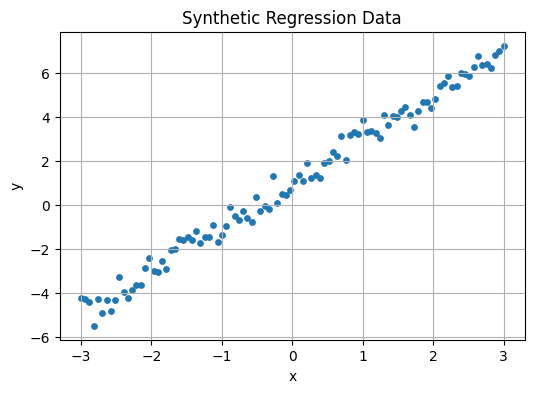

lr=0.001 | w=1.8771 | b=0.4379 | final loss=0.5427


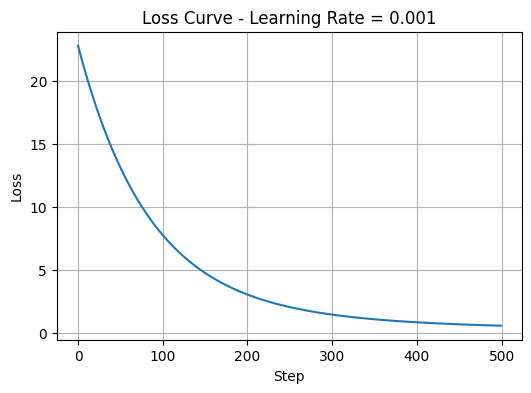

lr=0.05  | w=1.9961 | b=1.0239 | final loss=0.1541


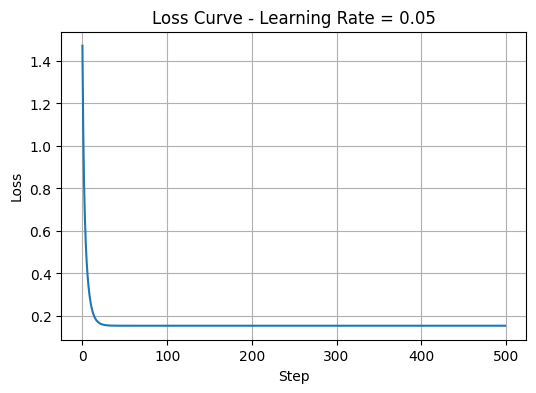

lr=1.0   | w=nan | b=nan | final loss=nan


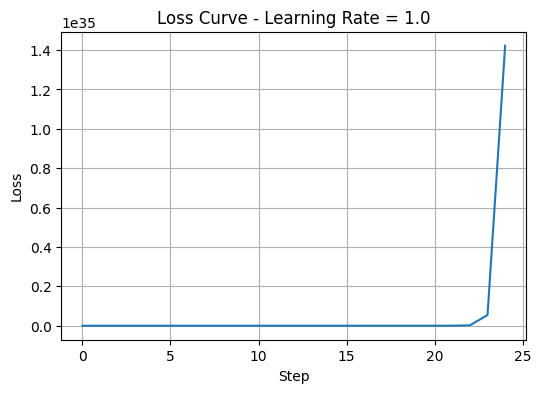

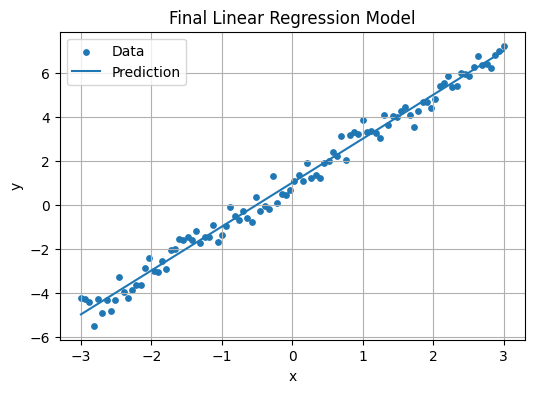


Final model:
w = 1.9961  (target ≈ 2)
b = 1.0239  (target ≈ 1)


In [ ]:
import torch
import matplotlib.pyplot as plt

# 1. Create synthetic data: y = 2x + 1 + noise
torch.manual_seed(42)

x = torch.linspace(-3, 3, 100).unsqueeze(1)
noise = 0.4 * torch.randn_like(x)
y = 2.0 * x + 1.0 + noise

# Plot the generated data
plt.figure(figsize=(6, 4))
plt.scatter(x.numpy(), y.numpy(), s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic Regression Data")
plt.grid(True)
plt.show()


# 2. Train function using Gradient Descent
def train(lr, steps=500):
    # Start w and b from random values
    # requires_grad=True allows PyTorch to calculate gradients
    w = torch.randn(1, requires_grad=True)
    b = torch.randn(1, requires_grad=True)

    loss_history = []

    for step in range(steps):

        # Forward pass: predict y using y = wx + b
        y_pred = w * x + b

        # Calculate Mean Squared Error (MSE)
        # Smaller loss means predictions are closer to real y
        loss = ((y_pred - y) ** 2).mean()

        # Backward pass: calculate dLoss/dw and dLoss/db
        loss.backward()

        # Update parameters using Gradient Descent
        # no_grad() prevents these updates from being tracked
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad

        # PyTorch accumulates gradients by default,
        # so we must reset them after every update
        w.grad.zero_()
        b.grad.zero_()

        # Save loss to plot the learning process later
        loss_history.append(loss.item())

    return w.item(), b.item(), loss_history


# 3. Experiment with different learning rates
learning_rates = [0.001, 0.05, 1.0]

for lr in learning_rates:

    # Train a new model for each learning rate
    w_final, b_final, losses = train(lr)

    print(
        f"lr={lr:<5} | "
        f"w={w_final:.4f} | "
        f"b={b_final:.4f} | "
        f"final loss={losses[-1]:.4f}"
    )

    # Plot Loss to see how fast the model learns
    plt.figure(figsize=(6, 4))
    plt.plot(losses)
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(f"Loss Curve - Learning Rate = {lr}")
    plt.grid(True)
    plt.show()


# 4. Use lr = 0.05 and visualize the final model
w_final, b_final, loss_history = train(0.05)

# Calculate final predictions
# no_grad() because we only want prediction, not gradients
with torch.no_grad():
    y_pred = w_final * x + b_final

# Plot real data and learned line
plt.figure(figsize=(6, 4))

plt.scatter(
    x.numpy(),
    y.numpy(),
    s=15,
    label="Data"
)

plt.plot(
    x.numpy(),
    y_pred.numpy(),
    label="Prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Final Linear Regression Model")
plt.legend()
plt.grid(True)
plt.show()

# Print the learned parameters
print("\nFinal model:")
print(f"w = {w_final:.4f}  (target ≈ 2)")
print(f"b = {b_final:.4f}  (target ≈ 1)")

#Ngày 5: nn.Module, loss function và optimizer

In [ ]:
import torch.nn as nn

model = nn.Linear(1, 1)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

loss_history_optimizer = []

for step in range(500):
    y_pred = model(x)

    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history_optimizer.append(loss.item())

    if step % 100 == 0:
        weight = model.weight.item()
        bias = model.bias.item()
        print(
            f"step={step:03d} "
            f"loss={loss.item():.4f} "
            f"w={weight:.4f} "
            f"b={bias:.4f}"
        )

step=000 loss=24.9997 w=0.0233 b=0.7252
step=100 loss=0.1541 w=1.9961 b=1.0239
step=200 loss=0.1541 w=1.9961 b=1.0239
step=300 loss=0.1541 w=1.9961 b=1.0239
step=400 loss=0.1541 w=1.9961 b=1.0239


step=000 loss=14.1372 w=0.7194 b=-0.6895
step=100 loss=0.1541 w=1.9961 b=1.0239
step=200 loss=0.1541 w=1.9961 b=1.0239
step=300 loss=0.1541 w=1.9961 b=1.0239
step=400 loss=0.1541 w=1.9961 b=1.0239


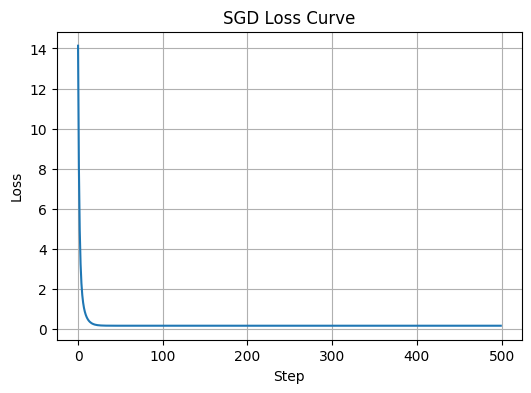

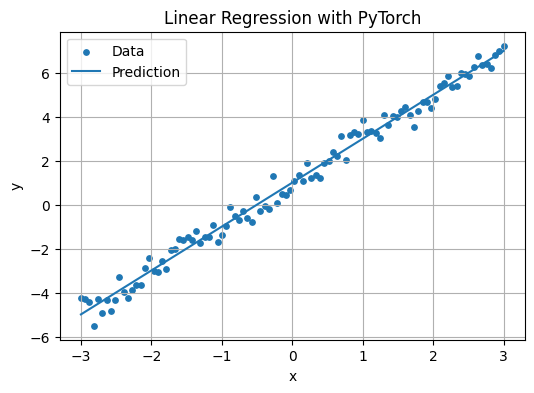


Final model:
weight = 1.9961  (target ≈ 2)
bias   = 1.0239  (target ≈ 1)


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================================
# 1. Create synthetic data: y = 2x + 1 + noise
# ============================================================
torch.manual_seed(42)

x = torch.linspace(-3, 3, 100).unsqueeze(1)
noise = 0.4 * torch.randn_like(x)
y = 2.0 * x + 1.0 + noise


# ============================================================
# 2. Create PyTorch model
# ============================================================
# Linear model: y = wx + b
model = nn.Linear(1, 1)

# Mean Squared Error loss
criterion = nn.MSELoss()

# SGD optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

loss_history = []


# ============================================================
# 3. Training loop
# ============================================================
for step in range(500):

    # Forward pass
    y_pred = model(x)

    # Calculate loss
    loss = criterion(y_pred, y)

    # Clear previous gradients
    optimizer.zero_grad()

    # Calculate gradients
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Save loss
    loss_history.append(loss.item())

    if step % 100 == 0:
        weight = model.weight.item()
        bias = model.bias.item()

        print(
            f"step={step:03d} "
            f"loss={loss.item():.4f} "
            f"w={weight:.4f} "
            f"b={bias:.4f}"
        )


# ============================================================
# 4. Plot loss curve
# ============================================================
plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("SGD Loss Curve")
plt.grid(True)
plt.show()


# ============================================================
# 5. Visualize learned line
# ============================================================
with torch.no_grad():
    y_pred = model(x)

plt.figure(figsize=(6, 4))

plt.scatter(
    x.numpy(),
    y.numpy(),
    s=15,
    label="Data"
)

plt.plot(
    x.numpy(),
    y_pred.numpy(),
    label="Prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression with PyTorch")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 6. Print final parameters
# ============================================================
print("\nFinal model:")
print(f"weight = {model.weight.item():.4f}  (target ≈ 2)")
print(f"bias   = {model.bias.item():.4f}  (target ≈ 1)")

so sánh SGD và Adam


=== SGD ===
weight = 1.9961
bias   = 1.0239
loss   = 0.1541

=== Adam ===
weight = 1.9961
bias   = 1.0239
loss   = 0.1541


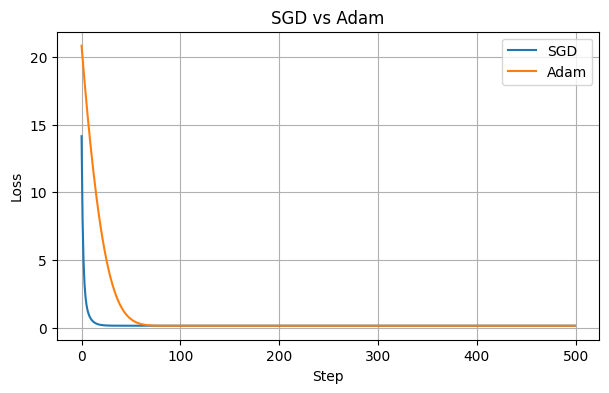

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


# ============================================================
# 1. Create the same dataset
# ============================================================
torch.manual_seed(42)

x = torch.linspace(-3, 3, 100).unsqueeze(1)
noise = 0.4 * torch.randn_like(x)
y = 2.0 * x + 1.0 + noise


# ============================================================
# 2. Training function
# ============================================================
def train(optimizer_name, lr=0.05, steps=500):

    # Create a new model
    model = nn.Linear(1, 1)

    # MSE loss
    criterion = nn.MSELoss()

    # Choose optimizer
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr
        )
    else:
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

    loss_history = []

    # Training loop
    for step in range(steps):

        # Forward
        y_pred = model(x)

        # Loss
        loss = criterion(y_pred, y)

        # Reset gradients
        optimizer.zero_grad()

        # Backward
        loss.backward()

        # Update parameters
        optimizer.step()

        loss_history.append(loss.item())

    return model, loss_history


# ============================================================
# 3. Train with SGD
# ============================================================
sgd_model, sgd_losses = train(
    "SGD",
    lr=0.05
)


# ============================================================
# 4. Train with Adam
# ============================================================
adam_model, adam_losses = train(
    "Adam",
    lr=0.05
)


# ============================================================
# 5. Compare final results
# ============================================================
print("=== SGD ===")
print(f"weight = {sgd_model.weight.item():.4f}")
print(f"bias   = {sgd_model.bias.item():.4f}")
print(f"loss   = {sgd_losses[-1]:.4f}")

print("\n=== Adam ===")
print(f"weight = {adam_model.weight.item():.4f}")
print(f"bias   = {adam_model.bias.item():.4f}")
print(f"loss   = {adam_losses[-1]:.4f}")


# ============================================================
# 6. Compare loss curves
# ============================================================
plt.figure(figsize=(7, 4))

plt.plot(sgd_losses, label="SGD")
plt.plot(adam_losses, label="Adam")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()